In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import imblearn
import numpy as np

import seaborn as sns
from sklearn import metrics
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
from sklearn.metrics import accuracy_score
from sklearn.metrics import accuracy_score
from imblearn.metrics import specificity_score
from sklearn.metrics import recall_score
from sklearn.metrics import precision_score
from sklearn.metrics import f1_score
from sklearn.ensemble import RandomForestClassifier

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer

In [36]:
car_df = pd.read_csv("second_hand_cars_deel1.csv")
detail_df = pd.read_csv("second_hand_cars_deel2.csv")

## Part 2. Exploring Data

### 2.1. Cars

In [16]:
car_df["Motor"].unique()

array(['  1.0 TSI  ', '  1.6 TDI  ', '1.5 hybrid', '1.8 hybrid',
       '1.0 ECOBOOST', '1.5 EcoBlue', '  0.9 TCe  ', '1.5 dci',
       '1.2 puretech', '1.5 BLUEHDI', '1.2 turbo', '  1.4 Turbo  ',
       '1.0 T-GDI', '1.6 CRDI', '1.0 MPI', '1.6 tdi', '1.0 hybrid',
       '1.2 dpi', '1.0 tce', '1.0 tsi', '1.0 TSI', '1.6 TDI',
       '1.5 HYBRID', '1.0 ecoboost', '1.5 ecoblue', '1.5 bluehdi',
       '1.2 TURBO', '1.4 turbo', '1.0 t-gdi', '1.6 crdi', '1.0 mpi',
       '  1.2 DPI  ', '1.0 TCe', '1.8 HYBRID', '1.5 ECOBLUE', '0.9 tce',
       '  1.5 dCi  ', '1.2 Turbo', '1.4 TURBO', '1.0 HYBRID', '1.2 DPI',
       '0.9 TCE', '  1.0 MPI  ', '  1.8 Hybrid  ', '1.5 DCI',
       '1.2 PURETECH', '1.5 BlueHDi', '1.0 Hybrid', '  1.2 Turbo  ',
       '  1.5 Hybrid  ', '  1.0 EcoBoost  ', '  1.2 PureTech  ',
       '1.0 TCE', '  1.5 EcoBlue  ', '  1.5 BlueHDi  ', '1.0 EcoBoost',
       '  1.0 T-GDI  ', '  1.0 Hybrid  ', '  1.0 TCe  ', '  1.6 CRDi  ',
       '1.8 Hybrid', '0.9 TCe', '1.5 Hybrid', '1.2

In [27]:
len(car_df["CHASSISNUMMER"].unique()) # Luckly. The only 'dirtyness' here comes from case inconsistancy, not (also) from spelling mistakes.

1000

In [5]:
car_df.describe()

,CHASSISNUMMER,Company Naam,Auto Namen,Motor,CC/Batterij
count,1000,1000,1000,1000,946
unique,1000,48,72,65,48
top,1HGYAKH1Z6C000000,Hyundai,500,1.6 tdi,999 CC
freq,1,40,47,58,74


In [6]:
car_df.dtypes

CHASSISNUMMER    object
Company Naam     object
Auto Namen       object
Motor            object
CC/Batterij      object
dtype: object

In [7]:
car_df.isna().sum()

CHASSISNUMMER     0
Company Naam      0
Auto Namen        0
Motor             0
CC/Batterij      54
dtype: int64

### 2.2. Car details

In [8]:
detail_df

,chassisnummer,Oorspronkelijke Catalogusprijs,Huidige Nieuwprijs,Leeftijd,Kilometerstand,Score,Conditie,Verbruik,Topsnelheid,Vermogen,Koppel,Huidige Verkoopprijs
0,WDDG15GGJXF000521,24290 EUR,€ 25.458,3,82191 km,5,1,9,139 km/h,107 hp,99,€ 13.425
1,WDDEVLP4RDB000737,€ 20.331,€31407,6 jaar,57543 km,1,5,9,172 km/u,99 PK,105 nm,€ 17.740
2,WP0ME5NNKM9000740,NaN,€25675,6 jaar,123028,3,7,11,140 km/u,103 PK,120 nm,€ 4.913 - € 5.323
3,1HG9CYPS3WR000660,€17779,€ 26.663,3,116587 km,3,2,14 km/l,NaN,90 pk,124 Nm,€ 5910
4,VF1S5W8C6T5000411,€ 22.959,€ 25.745 - € 27.891,5,50648,3,4,11,140,112,78 nm,€ 17.773
...,...,...,...,...,...,...,...,...,...,...,...,...
995,YV1025BCX79000106,18197 EUR,€ 27.615,4,66514,3,10,13 km/l,139,50 pk,69 Nm,€15338
996,JHMDUBG56SB000270,€ 21977,€ 30547,5,78.154,5,6,10,165 km/u,100 hp,124 Nm,€ 15.465
997,WP0KRT1DYME000860,22059 EUR,€26902,2,136449,2,6,15,192,120 hp,136 nm,€ 5.526
998,VF1U0DYJMZN000435,22826 EUR,€26491,3 jaar,96686 km,5,4,10,190 km/u,115 hp,140,€ 11.200


In [9]:
detail_df.describe()

,Score,Conditie
count,1000.000000,1000.000000
mean,2.988000,5.592000
std,1.402791,2.824449
min,1.000000,1.000000
25%,2.000000,3.000000
50%,3.000000,6.000000
75%,4.000000,8.000000
max,5.000000,10.000000


In [10]:
detail_df.dtypes

chassisnummer                     object
Oorspronkelijke Catalogusprijs    object
Huidige Nieuwprijs                object
Leeftijd                          object
Kilometerstand                    object
Score                              int64
Conditie                           int64
Verbruik                          object
Topsnelheid                       object
Vermogen                          object
Koppel                            object
Huidige Verkoopprijs              object
dtype: object

In [11]:
detail_df.isna().sum()

chassisnummer                      0
Oorspronkelijke Catalogusprijs    37
Huidige Nieuwprijs                28
Leeftijd                           0
Kilometerstand                    23
Score                              0
Conditie                           0
Verbruik                          47
Topsnelheid                       54
Vermogen                          32
Koppel                            63
Huidige Verkoopprijs              28
dtype: int64

### 2.3. Data cleaning steps required

#### Cars

- Company name: to lower case.
- Auto namen: to lower case.
- Motor: to lower case. Split version from motor type. Cast version number to float.
- CC/batterij: remove 'cc' from column. Cast to int.

(Any missing values uniformily marked as NAN)

#### Car details

- Oorspronkelijke catalogusprijs: remove monetary symbols / indicators. Define column name with EUR specification. Cast column to float.
- Huidige nieuwprijs: same as 'oorspronkelijke catalogusprijs' Cast to float
- leeftijd: remove all wording, keep only the actual number. Define column name with year specification. Cast to int
- verbuik: remove all wording, keep only the actual number. Define column name with 'km/l' specification. Cast to int
- topsnelheid: remove all wording, keep only the actual number. Define column name with 'km/h' specification. Cast to float
- vermogen: remove all wording, keep only the actual number. Convert all hp to pk. Define column name with "pk" specification. Cast to int.
- koppel: remove all wording, keep only the actual number. Define column name with 'nm' specification. Cast to int.
- huidige verkoopprijs: remove monetary symbols / indicators. Define column name with EUR specification. Cast to float.

<div>
<style scoped>
    .dataframe tbody tr th:only-of-type {
        vertical-align: middle;
    }

    .dataframe tbody tr th {
        vertical-align: top;
    }

    .dataframe thead th {
        text-align: right;
    }
</style>
<table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th></th>
      <th>chassisnummer</th>
      <th>Oorspronkelijke Catalogusprijs</th>
      <th>Huidige Nieuwprijs</th>
      <th>Leeftijd</th>
      <th>Kilometerstand</th>
      <th>Score</th>
      <th>Conditie</th>
      <th>Verbruik</th>
      <th>Topsnelheid</th>
      <th>Vermogen</th>
      <th>Koppel</th>
      <th>Huidige Verkoopprijs</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th>0</th>
      <td>WDDG15GGJXF000521</td>
      <td>24290 EUR</td>
      <td>€ 25.458</td>
      <td>3</td>
      <td>82191 km</td>
      <td>5</td>
      <td>1</td>
      <td>9</td>
      <td>139 km/h</td>
      <td>107 hp</td>
      <td>99</td>
      <td>€ 13.425</td>
    </tr>
    <tr>
      <th>1</th>
      <td>WDDEVLP4RDB000737</td>
      <td>€ 20.331</td>
      <td>€31407</td>
      <td>6 jaar</td>
      <td>57543 km</td>
      <td>1</td>
      <td>5</td>
      <td>9</td>
      <td>172 km/u</td>
      <td>99 PK</td>
      <td>105 nm</td>
      <td>€ 17.740</td>
    </tr>
    <tr>
      <th>2</th>
      <td>WP0ME5NNKM9000740</td>
      <td>NaN</td>
      <td>€25675</td>
      <td>6 jaar</td>
      <td>123028</td>
      <td>3</td>
      <td>7</td>
      <td>11</td>
      <td>140 km/u</td>
      <td>103 PK</td>
      <td>120 nm</td>
      <td>€ 4.913 - € 5.323</td>
    </tr>
    <tr>
      <th>3</th>
      <td>1HG9CYPS3WR000660</td>
      <td>€17779</td>
      <td>€ 26.663</td>
      <td>3</td>
      <td>116587 km</td>
      <td>3</td>
      <td>2</td>
      <td>14 km/l</td>
      <td>NaN</td>
      <td>90 pk</td>
      <td>124 Nm</td>
      <td>€ 5910</td>
    </tr>
    <tr>
      <th>4</th>
      <td>VF1S5W8C6T5000411</td>
      <td>€ 22.959</td>
      <td>€ 25.745 - € 27.891</td>
      <td>5</td>
      <td>50648</td>
      <td>3</td>
      <td>4</td>
      <td>11</td>
      <td>140</td>
      <td>112</td>
      <td>78 nm</td>
      <td>€ 17.773</td>
    </tr>
    <tr>
      <th>...</th>
      <td>...</td>
      <td>...</td>
      <td>...</td>
      <td>...</td>
      <td>...</td>
      <td>...</td>
      <td>...</td>
      <td>...</td>
      <td>...</td>
      <td>...</td>
      <td>...</td>
      <td>...</td>
    </tr>
    <tr>
      <th>995</th>
      <td>YV1025BCX79000106</td>
      <td>18197 EUR</td>
      <td>€ 27.615</td>
      <td>4</td>
      <td>66514</td>
      <td>3</td>
      <td>10</td>
      <td>13 km/l</td>
      <td>139</td>
      <td>50 pk</td>
      <td>69 Nm</td>
      <td>€15338</td>
    </tr>
    <tr>
      <th>996</th>
      <td>JHMDUBG56SB000270</td>
      <td>€ 21977</td>
      <td>€ 30547</td>
      <td>5</td>
      <td>78.154</td>
      <td>5</td>
      <td>6</td>
      <td>10</td>
      <td>165 km/u</td>
      <td>100 hp</td>
      <td>124 Nm</td>
      <td>€ 15.465</td>
    </tr>
    <tr>
      <th>997</th>
      <td>WP0KRT1DYME000860</td>
      <td>22059 EUR</td>
      <td>€26902</td>
      <td>2</td>
      <td>136449</td>
      <td>2</td>
      <td>6</td>
      <td>15</td>
      <td>192</td>
      <td>120 hp</td>
      <td>136 nm</td>
      <td>€ 5.526</td>
    </tr>
    <tr>
      <th>998</th>
      <td>VF1U0DYJMZN000435</td>
      <td>22826 EUR</td>
      <td>€26491</td>
      <td>3 jaar</td>
      <td>96686 km</td>
      <td>5</td>
      <td>4</td>
      <td>10</td>
      <td>190 km/u</td>
      <td>115 hp</td>
      <td>140</td>
      <td>€ 11.200</td>
    </tr>
    <tr>
      <th>999</th>
      <td>JHM2B103NY4000102</td>
      <td>€ 21.027</td>
      <td>30030 EUR</td>
      <td>2 jaar</td>
      <td>118.272</td>
      <td>4</td>
      <td>10</td>
      <td>9</td>
      <td>152 km/u</td>
      <td>118 pk</td>
      <td>79 nm</td>
      <td>€ 10.315 - € 11.175</td>
    </tr>
  </tbody>
</table>
<p>1000 rows × 12 columns</p>
</div>

## Stap 3. Pre-processing

"Prepare for the great clean-age"

### car_df cleaning

In [77]:
car_df = pd.read_csv("second_hand_cars_deel1.csv")

for col in car_df.columns:
    if col == "CHASSISNUMMER":
        new_col = col.lower().replace(" ", "_")
        car_df = car_df.rename(columns={col: new_col})
    else:
        car_df[col] = car_df[col].str.lower()
        car_df[col] = car_df[col].str.strip()

        new_col = col.lower().replace(" ", "_")
        car_df = car_df.rename(columns={col: new_col})

car_df["cc/batterij"] = car_df["cc/batterij"].str.replace(r"\D", " ", regex=True)

car_df[["motor_version", "motor_type"]] = (
    car_df["motor"].str.split(" ", n=1, expand=True)
)
car_df = car_df.drop(columns=["motor"])

car_df["motor_version"] = car_df["motor_version"].astype(float)
car_df["cc/batterij"] = car_df["cc/batterij"].astype(float)

In [78]:
car_df

,chassisnummer,company_naam,auto_namen,cc/batterij,motor_version,motor_type
0,1HGYAKH1Z6C000000,volkswagen,polo,999.0,1.0,tsi
1,WAUPAHTAGYU000001,volkswagen,golf,1598.0,1.6,tdi
2,WBAHW3A30MF000002,toyota,yaris,1490.0,1.5,hybrid
3,VF18MDD4W31000003,toyota,corolla,1798.0,1.8,hybrid
4,ZARU9NV4X5W000004,ford,fiesta,998.0,1.0,ecoboost
...,...,...,...,...,...,...
995,SHSP4JK8YNL000995,skoda,octavia,1598.0,1.6,tdi
996,1HGP51CX2ME000996,fiat,500,999.0,1.0,hybrid
997,WAU17PL93AC000997,kia,rio,1197.0,1.2,dpi
998,WBAZUY1FN0G000998,dacia,sandero,999.0,1.0,tce


### details_df cleaning

In [75]:
import regex as re

detail_df = pd.read_csv("second_hand_cars_deel2.csv")
units = {
    "Oorspronkelijke Catalogusprijs": "(EUR)",
    "Huidige Nieuwprijs": "(EUR)",
    "Leeftijd": "(jaar)",
    "Kilometerstand": "(KM)",
    "Topsnelheid": "(KM/h)",
    "Huidige Verkoopprijs": "(EUR)",
    "Vermogen": "(pK)",
    "Koppel": "(Nm)",
    "Score": "(1-10)",
    "Conditie": "(1-10)"
}

def convert_vermogen(x):
    altered_series = x.copy()
    for idx, item in altered_series.items():
        item = str(item)
        find_unit = re.findall(r"pk|hp", item, flags=re.IGNORECASE)

        if not find_unit:
            altered_series.loc[idx] = np.nan # => If the unit is unkown, then the entier cell is treated as such. Because it could say '60', but what is '60'? There is no way of knowing, except if you assume it is automatically then pK or Hp.
        else:
            unit = str(find_unit[0]).lower()
            number = int(re.sub(r"\D", "", item))

            if(unit == "pk"):
                altered_series.loc[idx] = number
            else:
                converted_number = round(number * 1.01387, 0)
                altered_series.loc[idx] = converted_number
    return pd.to_numeric(altered_series, errors="coerce")
        

def keep_digits(x):
    altered_series = x.copy()
    for idx, item in altered_series.items():
        item = str(item)

        digit_delete = re.sub(r"\D", "", item)

        if digit_delete == "":
            altered_series.loc[idx] = np.nan
        elif "-" not in item:
            altered_series.loc[idx] = float(digit_delete)
        else:
            ratios = re.findall(r"[\d.]+", item)

            if(len(ratios) >= 2):
                price1 = float(ratios[0].replace(".", ""))
                price2 = float(ratios[1].replace(".", ""))

                newprice = price1 + ((price2 - price1)/2)
                altered_series.loc[idx] = float(newprice)

            else:
                altered_series.loc[idx] = float(digit_delete)
    numseries = pd.to_numeric(altered_series, errors="coerce")
    return round(numseries, 2)

def standard_cols(df):
    for col in df.columns:
        new_col = ""

        if(col in units):
            unit_fetch = units[col]
            new_col = f"{col.lower().replace(" ", "_")} {unit_fetch}"
        else:
            new_col = f"{col.lower().replace(" ", "_")}"
        df = df.rename(columns={col: new_col})
    return df

excl_cols = ["chassisnummer", "vermogen"]

for col in detail_df.columns:
    if col.lower() in excl_cols:
        pass
    else:
        try:
            detail_df[col] = keep_digits(detail_df[col])
        except Exception as e:
            print(f"\nColumn: {col}")
            print(f"Error: {e}")
            raise

detail_df = standard_cols(detail_df)
print(detail_df.columns)
detail_df["vermogen (pK)"] = convert_vermogen(detail_df["vermogen (pK)"])

detail_df

Index(['chassisnummer', 'oorspronkelijke_catalogusprijs (EUR)',
       'huidige_nieuwprijs (EUR)', 'leeftijd (jaar)', 'kilometerstand (KM)',
       'score (1-10)', 'conditie (1-10)', 'verbruik', 'topsnelheid (KM/h)',
       'vermogen (pK)', 'koppel (Nm)', 'huidige_verkoopprijs (EUR)'],
      dtype='object')


,chassisnummer,oorspronkelijke_catalogusprijs (EUR),huidige_nieuwprijs (EUR),leeftijd (jaar),kilometerstand (KM),score (1-10),conditie (1-10),verbruik,topsnelheid (KM/h),vermogen (pK),koppel (Nm),huidige_verkoopprijs (EUR)
0,WDDG15GGJXF000521,24290.0,25458.0,3.0,82191.0,5,1,9.0,139.0,108.0,99.0,13425.0
1,WDDEVLP4RDB000737,20331.0,31407.0,6.0,57543.0,1,5,9.0,172.0,99.0,105.0,17740.0
2,WP0ME5NNKM9000740,NaN,25675.0,6.0,123028.0,3,7,11.0,140.0,103.0,120.0,5118.0
3,1HG9CYPS3WR000660,17779.0,26663.0,3.0,116587.0,3,2,14.0,NaN,90.0,124.0,5910.0
4,VF1S5W8C6T5000411,22959.0,26818.0,5.0,50648.0,3,4,11.0,140.0,NaN,78.0,17773.0
...,...,...,...,...,...,...,...,...,...,...,...,...
995,YV1025BCX79000106,18197.0,27615.0,4.0,66514.0,3,10,13.0,139.0,50.0,69.0,15338.0
996,JHMDUBG56SB000270,21977.0,30547.0,5.0,78154.0,5,6,10.0,165.0,101.0,124.0,15465.0
997,WP0KRT1DYME000860,22059.0,26902.0,2.0,136449.0,2,6,15.0,192.0,122.0,136.0,5526.0
998,VF1U0DYJMZN000435,22826.0,26491.0,3.0,96686.0,5,4,10.0,190.0,117.0,140.0,11200.0


## Connecting the DF's

In [79]:
car_df
detail_df

car_detail_df = pd.merge(
    car_df,
    detail_df,
    on="chassisnummer",
    how="inner"
)

car_detail_df

,chassisnummer,company_naam,auto_namen,cc/batterij,motor_version,motor_type,oorspronkelijke_catalogusprijs (EUR),huidige_nieuwprijs (EUR),leeftijd (jaar),kilometerstand (KM),score (1-10),conditie (1-10),verbruik,topsnelheid (KM/h),vermogen (pK),koppel (Nm),huidige_verkoopprijs (EUR)
0,1HGYAKH1Z6C000000,volkswagen,polo,999.0,1.0,tsi,18748.0,27937.0,3.0,78945.0,1,2,14.0,177.0,73.0,123.0,12296.0
1,WAUPAHTAGYU000001,volkswagen,golf,1598.0,1.6,tdi,20717.0,30137.0,6.0,NaN,5,9,9.0,148.0,NaN,95.0,9975.0
2,WBAHW3A30MF000002,toyota,yaris,1490.0,1.5,hybrid,24045.0,26977.0,2.0,132538.0,2,8,NaN,181.0,53.0,97.0,7539.0
3,VF18MDD4W31000003,toyota,corolla,1798.0,1.8,hybrid,20090.0,25283.0,4.0,101065.0,4,3,11.0,197.0,54.0,116.0,8550.0
4,ZARU9NV4X5W000004,ford,fiesta,998.0,1.0,ecoboost,24199.0,28397.0,6.0,61559.0,3,9,12.0,160.0,NaN,105.0,18589.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,SHSP4JK8YNL000995,skoda,octavia,1598.0,1.6,tdi,22163.0,26035.0,5.0,125092.0,1,6,11.0,171.0,95.0,97.0,6676.0
996,1HGP51CX2ME000996,fiat,500,999.0,1.0,hybrid,20987.0,29687.0,4.0,83370.0,2,9,14.0,161.0,101.0,120.0,14691.0
997,WAU17PL93AC000997,kia,rio,1197.0,1.2,dpi,22622.0,29496.0,7.0,86722.0,1,8,NaN,196.0,115.0,89.0,14205.0
998,WBAZUY1FN0G000998,dacia,sandero,999.0,1.0,tce,18745.0,25635.0,2.0,140478.0,4,5,9.0,184.0,112.0,128.0,2604.0


With this data, we can now train a machine learning model on it.

Let's assume the variable we want to predict is the current selling price.

In order to know what variables have a strong correlation to our target variable, we will map the correlation of our dataframe in a heatmap.

### Data relevance (linear regression)

<Axes: >

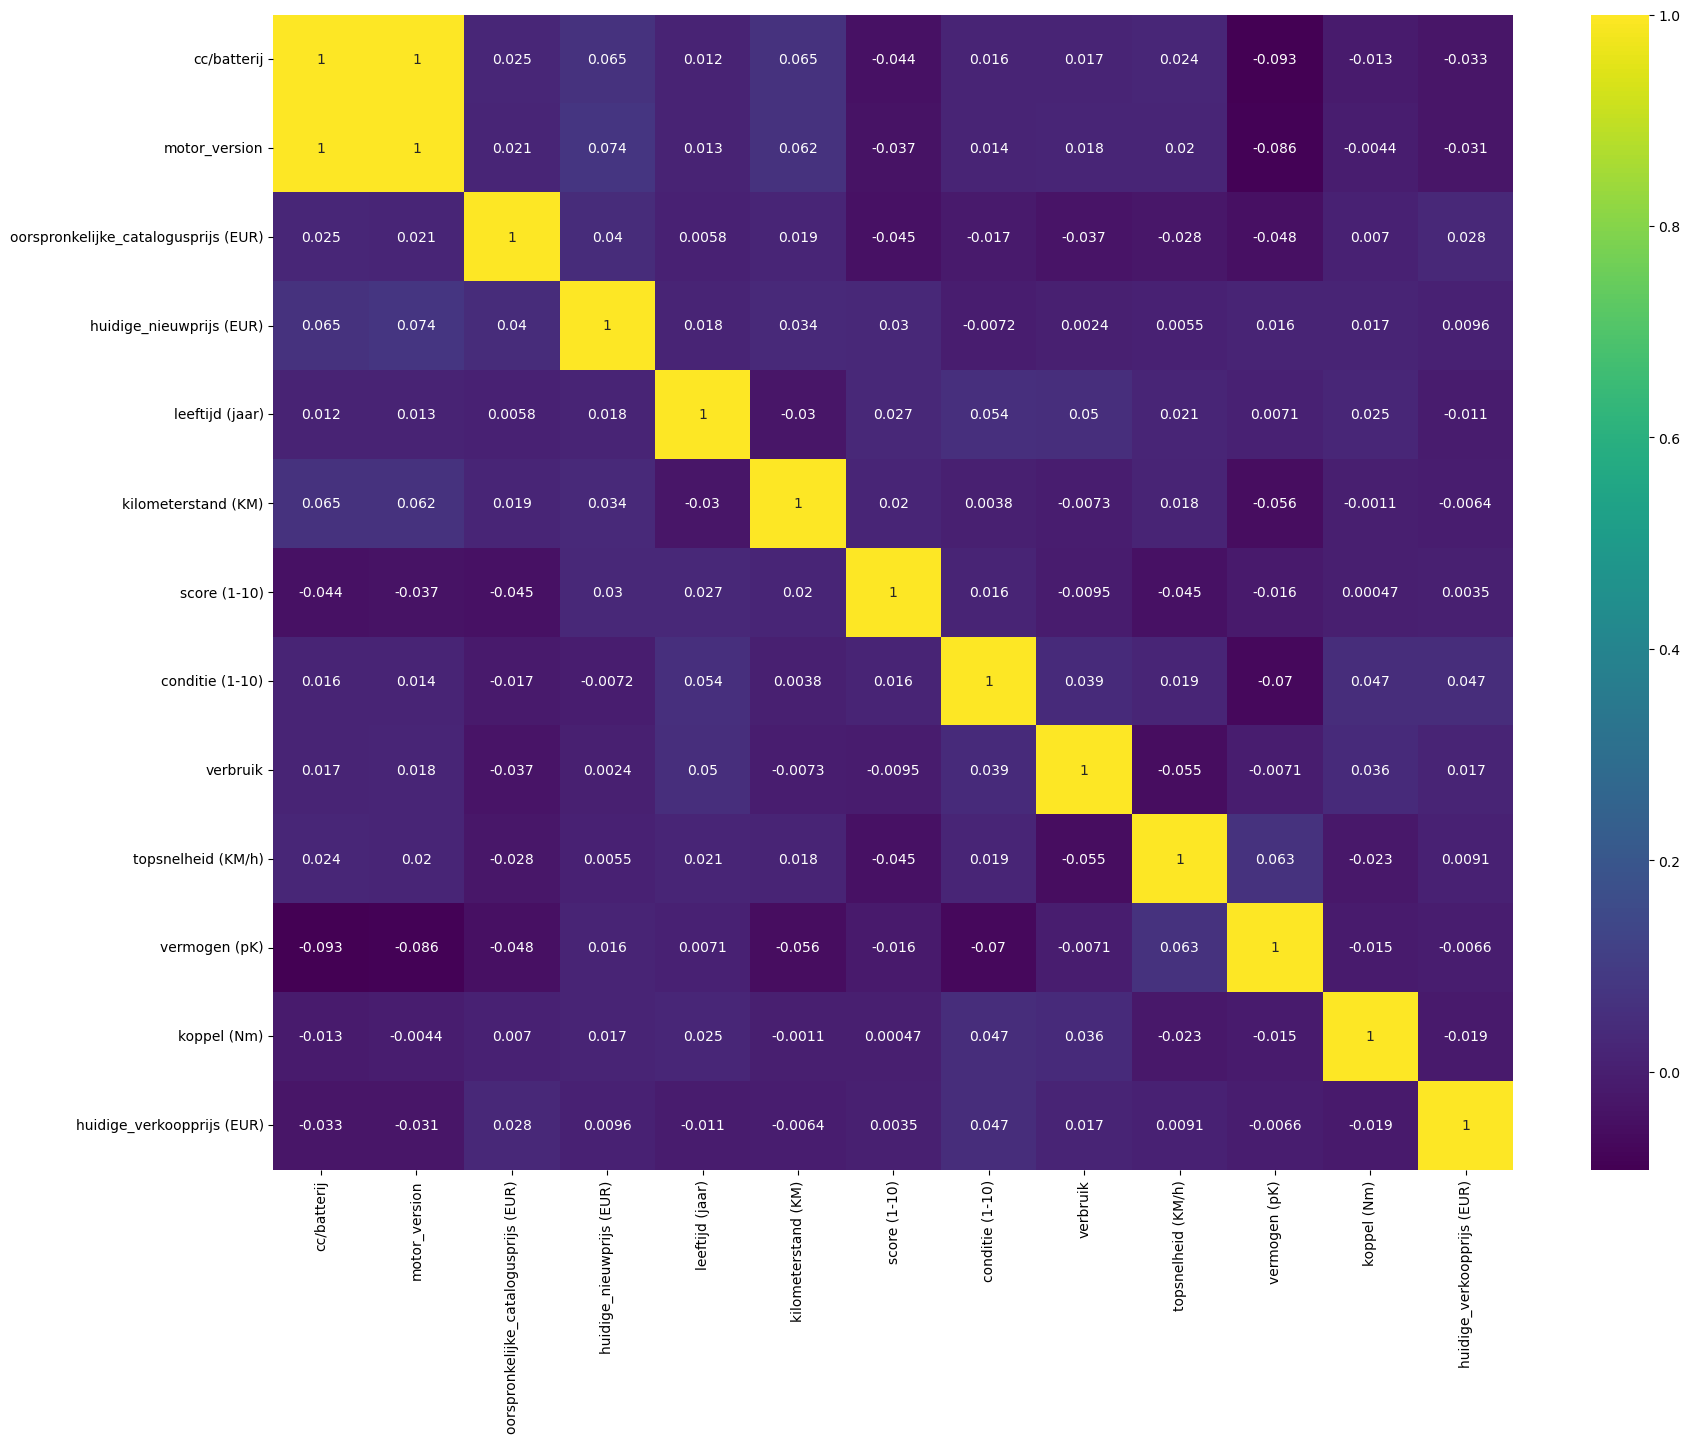

In [85]:
plt.figure(figsize=[20,15])
corr_def = car_detail_df.drop(columns=["chassisnummer", "company_naam", "auto_namen", "motor_type"], axis=1)
df_corr = corr_def.corr()
sns.heatmap(df_corr, annot=True, cmap="viridis")

Strangly, the correlations seem to be rather weak all around. Except for motor version and battery, which likely means nothing.

This could be because our relations are not linear. Therefore: we will try to use the spearman method instead to calculate our correlation

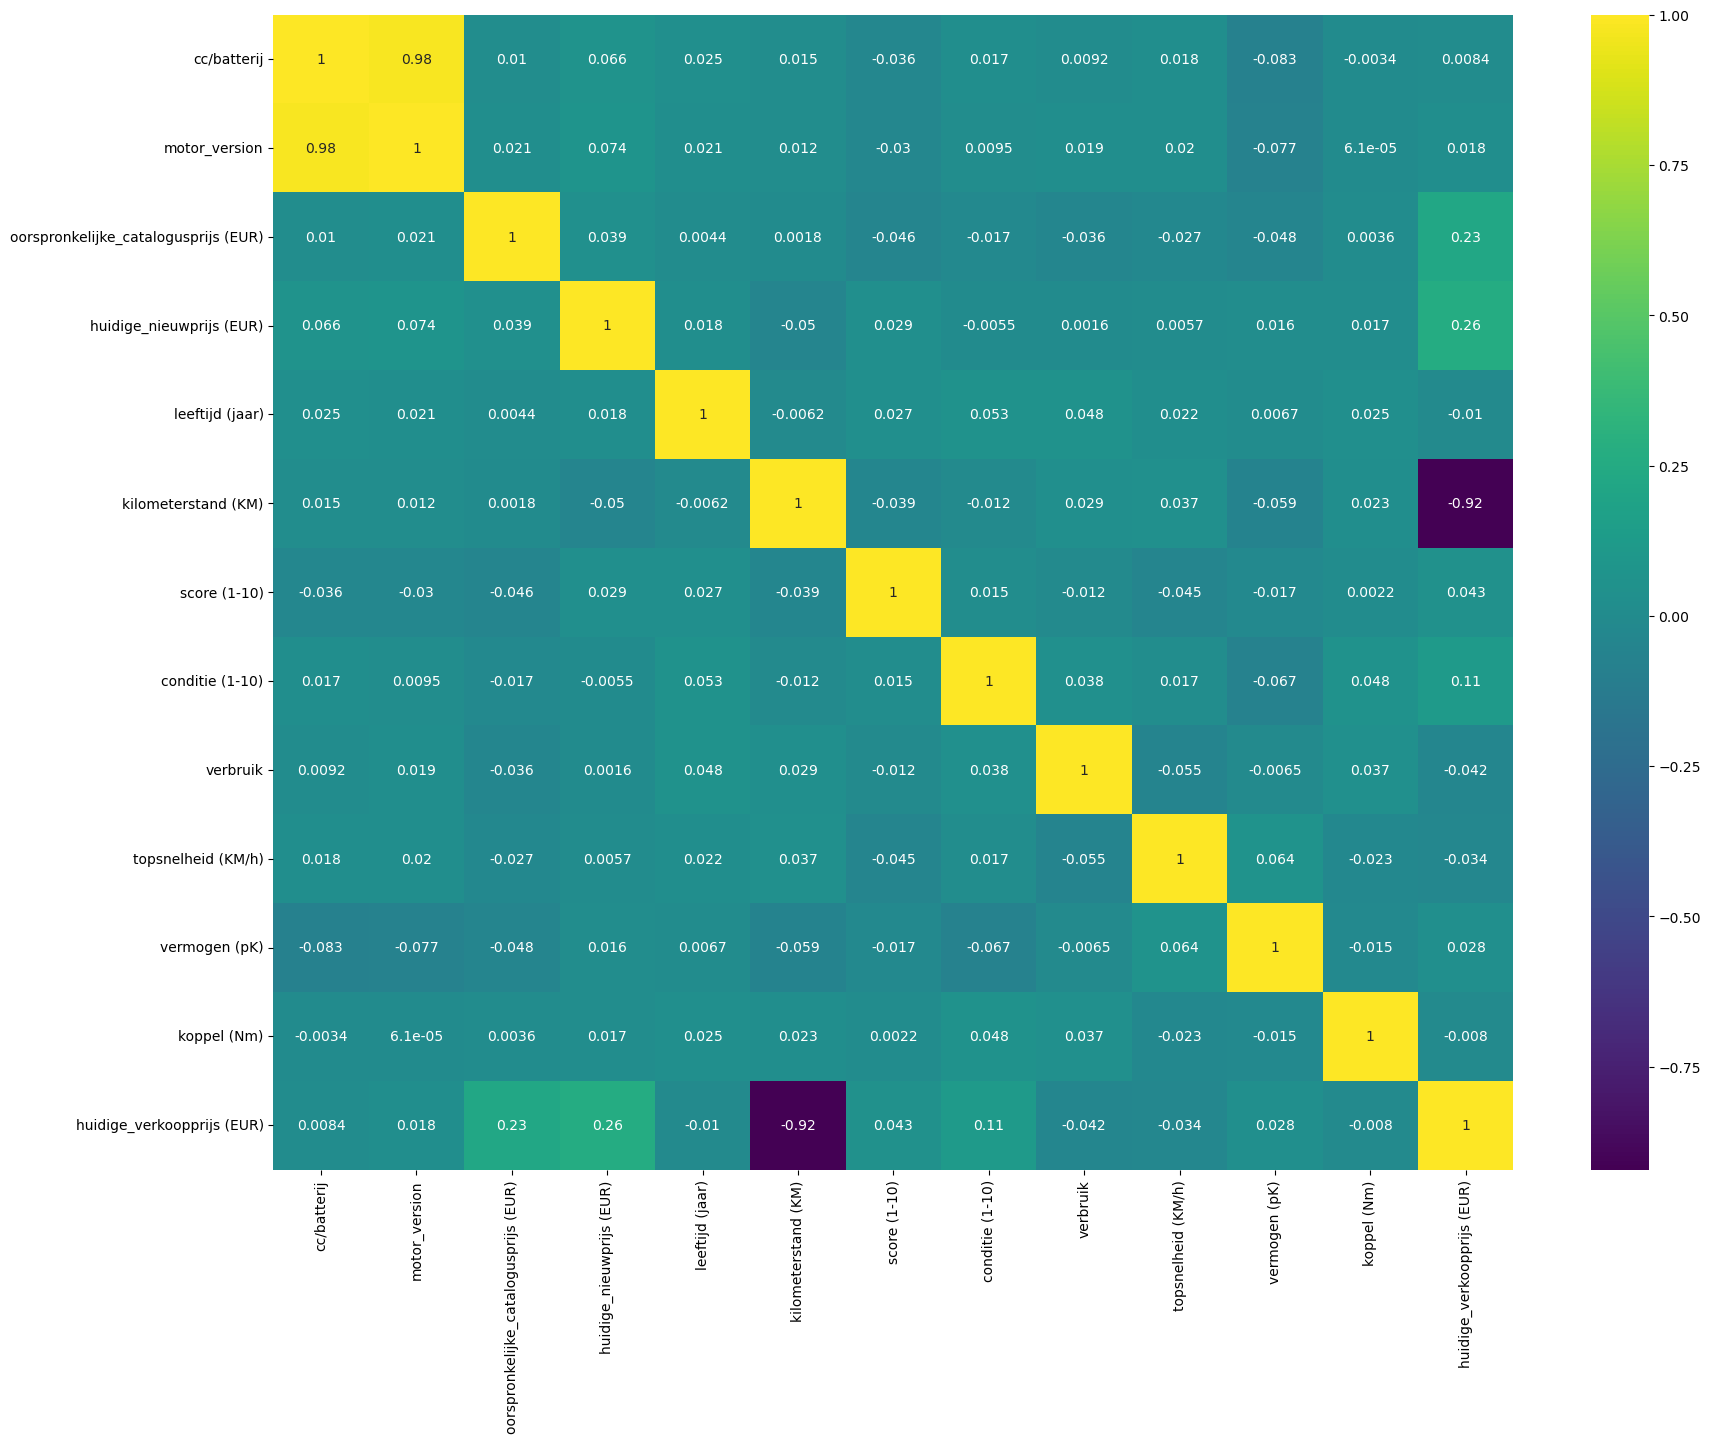

In [87]:
plt.figure(figsize=[20,15])
spearman_corr = car_detail_df.select_dtypes(
    include="number"
).corr(method="spearman")

sns.heatmap(spearman_corr, annot=True, cmap="viridis")
plt.show()

Now we can see something very interesting. There is an extremely high negative correlation between verkoopprijs and kilometerstand. This makes sense as the more kilometers a car has driver, the less it is worth overall. Though the correlation seems a bit... too strong, let's investigate this further with a scatterplot

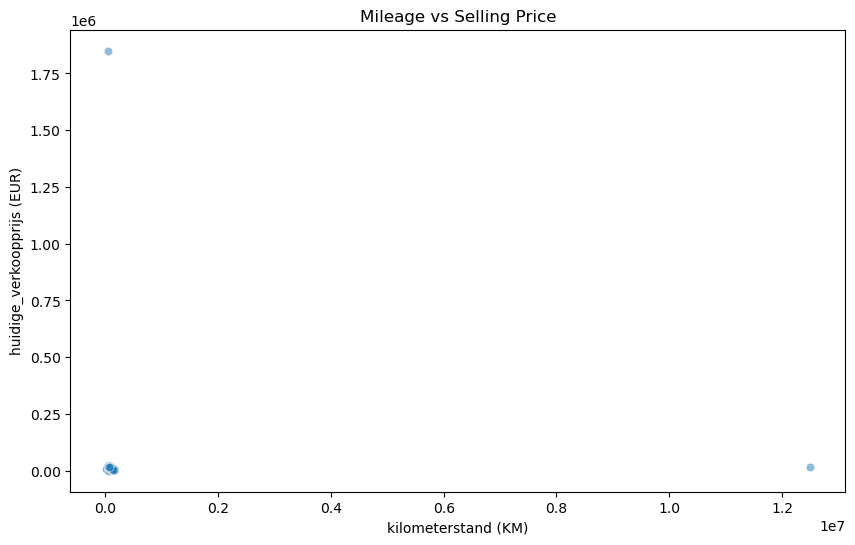

In [94]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=car_detail_df,
    x="kilometerstand (KM)",
    y="huidige_verkoopprijs (EUR)",
    alpha=0.5
)

plt.title("Mileage vs Selling Price")
plt.show()

What is happening here: is that some extreme outliers are forcing the graph to drastically zoom out, causing a confusing view of the datapoints.

Simply adding a filter to this visualization will be more revealing about the relation between the 2 variables.

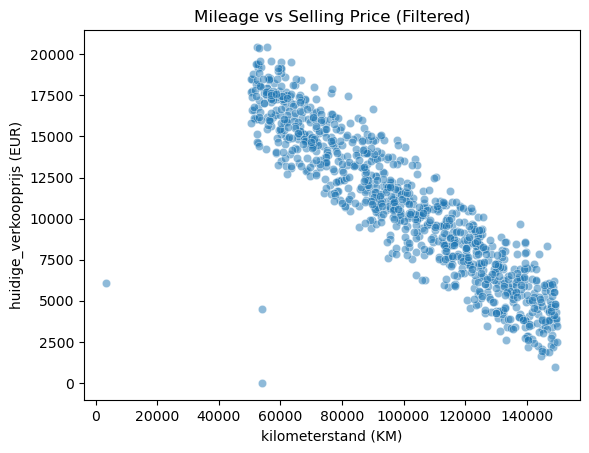

In [93]:
filtered_df = car_detail_df[
    (car_detail_df["kilometerstand (KM)"] < 500000) &
    (car_detail_df["huidige_verkoopprijs (EUR)"] < 200000)
]

sns.scatterplot(
    data=filtered_df,
    x="kilometerstand (KM)",
    y="huidige_verkoopprijs (EUR)",
    alpha=0.5
)

plt.title("Mileage vs Selling Price (Filtered)")
plt.show()

Now it has become clear, that there is in fact a very strong negative relation between the 2 variables. This is likely correct, though we need to remain wary of outliers.

## Training a model